# El padró de Barcelona: una anàlisi demogràfica amb Python

+ **Assignatura:** Taller de Nous Usos de la Informàtica (TNUI)
+ **Durada estimada:** 4 hores
+ **Eines:** Python · pandas · matplotlib
+ **Dades:** Padró Municipal d'Habitants · Ajuntament de Barcelona (Open Data BCN)

---

## Objectius d'aprenentatge

Al final d'aquesta pràctica seràs capaç de:

1. **Carregar i explorar** fitxers CSV reals amb pandas.
2. **Identificar i gestionar** valors nuls i dades emmascades.
3. **Unir** múltiples fitxers en un únic DataFrame coherent.
4. **Transformar i agregar** dades per obtenir indicadors demogràfics.
5. **Visualitzar** tendències temporals i distribucions amb matplotlib.
6. **Comunicar** resultats amb claredat, justificant cada decisió.


> **Nota:** Les cel·les marcades amb 🔧 contenen codi que has d'escriure o completar.
> Les marcades amb ✅ ja estan resoltes i serveixen de guia.


## Com trobar ajuda sobre pandas

  Dins del notebook (la manera més ràpida):
  
  + `df.groupby?`          # docstring del mètode
  + `help(pd.merge)`       # documentació completa
  + `pd.DataFrame.<TAB>`   # autocompletat de mètodes
  
  Referència oficial:
  - Guia d'usuari (https://pandas.pydata.org/docs/user_guide/index.html) — conceptes amb exemples (filtratge, agrupació, joins…)
  - API Reference (https://pandas.pydata.org/docs/reference/index.html) — tots els mètodes, paràmetre per paràmetre

  Full de ruta ràpid:
  - Pandas Cheat Sheet (PDF) (https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf) — les operacions més habituals en una pàgina

  Quan estàs encallat:
  1. Comprova l'estat de les dades amb `df.info()`, `df.head()` i `df.dtypes`.
  2. Descriu el problema a la IA amb: quines columnes tens + quin resultat esperes.

  ---
## Com trobar ajuda sobre matplotlib

  Dins del notebook:
  + `plt.plot?`            # docstring de la funció
  + `help(plt.subplots)`   # paràmetres detallats
  
  Referència oficial:
  - Tutorials per a principiants (https://matplotlib.org/stable/tutorials/index.html) — des de la primera figura fins a subplots avançats
  - API Reference: pyplot (https://matplotlib.org/stable/api/pyplot_summary.html) — totes les funcions de plt.*
  - Galeria d'exemples (https://matplotlib.org/stable/gallery/index.html) — busca el tipus de gràfic que necessites i copia el codi

  Patrons habituals en aquesta pràctica:
  ```python
  fig, ax = plt.subplots(figsize=(10, 5))
  ax.plot(x, y, color="steelblue", label="Sèrie A")
  ax.bar(categories, valors, color="salmon")
  ax.set_title("Títol")
  ax.set_xlabel("Eix X"); ax.set_ylabel("Eix Y")
  ax.legend()
  ax.yaxis.set_major_formatter(
      plt.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))  # format milers
  plt.tight_layout()
  plt.savefig("grafic.png", bbox_inches="tight", dpi=150)
  ```
  
  Quan estàs encallat:
  - Matplotlib Cheat Sheets (PDF) (https://matplotlib.org/cheatsheets/) — 3 fulls: beginner, intermediate, tips & tricks
  - Cerca a la galeria pel tipus de gràfic: línia, barres, àrea apilada, scatter…


## Configuració inicial

Executa aquesta cel·la abans de començar. Importa les biblioteques necessàries i defineix les rutes de dades.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import glob
import os

# Ruta base de les dades (ajusta si cal)
BASE = "./data"
PATH_POBLACIO  = os.path.join(BASE, "poblacio_lloc_naix")
PATH_EDAT      = os.path.join(BASE, "edat_lloc_naix")
PATH_DOMICILIS = os.path.join(BASE, "domicilis_estructura")
PATH_DIMS      = os.path.join(BASE, "pad_dimensions.csv")

# Estil de gràfics
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
})

print("✓ Configuració carregada correctament")


✓ Configuració carregada correctament



## Part 1 — Exploració inicial: un sol any (2026)

Comencem carregant **un únic fitxer** per entendre l'estructura de les dades
abans d'escalar a tota la sèrie temporal.


### 1.1 ✅ Càrrega del fitxer

El dataset `poblacio_lloc_naix` conté el cens agregat per lloc de
naixement i sexe, a nivell de **secció censal**, per a cada barri i districte
de Barcelona. Hi ha **un fitxer CSV per any** (1997–2026).

> Busca la definició de secció censal.


In [2]:
# ✅ Exemple de càrrega — executeu per veure l'estructura
df_2026 = pd.read_csv(os.path.join(PATH_POBLACIO, "2026_poblacio_lloc_naix.csv"))
print("Shape:", df_2026.shape)
print()
df_2026.head(8)


Shape: (11082, 10)



,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,AEB,Seccio_Censal,Valor,LLOC_NAIX,SEXE
0,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,158,1,1
1,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,171,1,2
2,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,36,2,1
3,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,23,2,2
4,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,68,3,1
5,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,82,3,2
6,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,55,4,1
7,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,60,4,2


### 1.2 🔧 Inspecció bàsica

Respon les preguntes següents explorant el DataFrame. Escriu codi a cada cel·la.


**a) Quines columnes té el dataset i de quin tipus és cadascuna?**

In [3]:
print("Columnes:", df_2026.columns.tolist())
print("\nTipus de dades:")
print(df_2026.dtypes)

Columnes: ['Data_Referencia', 'Codi_Districte', 'Nom_Districte', 'Codi_Barri', 'Nom_Barri', 'AEB', 'Seccio_Censal', 'Valor', 'LLOC_NAIX', 'SEXE']

Tipus de dades:
Data_Referencia    object
Codi_Districte      int64
Nom_Districte      object
Codi_Barri          int64
Nom_Barri          object
AEB                 int64
Seccio_Censal       int64
Valor              object
LLOC_NAIX           int64
SEXE                int64
dtype: object


**b) Quants valors nuls hi ha per columna?**

> Busca la definició de valor nul de pandas. Tingues en compte que si hi ha valors nuls que no tenen aquets format no els detectarà com a valors nuls.

In [4]:
print(df_2026.isna().sum())

Data_Referencia    0
Codi_Districte     0
Nom_Districte      0
Codi_Barri         0
Nom_Barri          0
AEB                0
Seccio_Censal      0
Valor              0
LLOC_NAIX          0
SEXE               0
dtype: int64


**c) La columna `Valor` hauria de ser numèrica, però pot contenir el caràcter `..`
(dada emmascada per protecció de la privacitat quan el recompte és molt baix).
Quantes files contenen `..`? Quin percentatge representen?**

> Per que creus que l'ajuntament ha d'emmascarar dades?


In [5]:
# 🔧 1.2.c — Valors emmascarats ("..") a la columna Valor
# Com que Valor conté el text "..", pandas l'ha llegit com a text (str), no com a número.
# Per això isna() no els detecta: per a pandas ".." és un text vàlid, no un nul.

n_total = len(df_2026)                          # nombre total de files del fitxer
n_emmascarats = (df_2026["Valor"] == "..").sum()  # True per a cada fila amb "..", i sum() compta els True
pct_emmascarats = n_emmascarats / n_total * 100   # percentatge sobre el total de files

print(f"Files totals:          {n_total:,}")
print(f"Files amb '..':        {n_emmascarats:,}")
print(f"Percentatge amb '..':  {pct_emmascarats:.2f} %")

# Per què s'emmascaren?
# Quan en una secció censal hi ha molt poques persones d'una categoria (p. ex. 1 o 2 dones
# nascudes a la UE), publicar el número exacte podria permetre identificar-les.
# L'Ajuntament substitueix aquests recomptes petits per ".." per protegir la privacitat
# (secret estadístic), a canvi de perdre una mica de precisió.

Files totals:          11,082
Files amb '..':        412
Percentatge amb '..':  3.72 %


**d) Quants valors únics té la columna `LLOC_NAIX`?
Llista'ls. Com interpretes aquest resultat?**

> 💡 *Pista:* Consulta el fitxer `pad_dimensions.csv` per entendre els codis.


In [6]:
# 🔧 1.2.d — Valors únics de LLOC_NAIX
codis_lloc = sorted(df_2026["LLOC_NAIX"].unique())   # llista ordenada dels codis diferents

print("Nombre de valors únics:", df_2026["LLOC_NAIX"].nunique())
print("Valors:", [int(c) for c in codis_lloc])       # int() només perquè es vegin nets

# Quantes files hi ha de cada codi (ajuda a interpretar-los)
print("\nFiles per codi:")
print(df_2026["LLOC_NAIX"].value_counts().sort_index())

# Interpretació:
# Hi ha 6 codis (1–6). No són llocs concrets sinó grans grups de lloc de naixement
# (Barcelona, resta de Catalunya, resta d'Espanya, resta de la UE, resta del món i "no consta").
# Els codis 1–5 apareixen a gairebé totes les seccions (2 files per secció: una per sexe),
# mentre que el codi 6 en té molt poques: només surt on hi ha algú sense lloc de naixement registrat.

Nombre de valors únics: 6
Valors: [1, 2, 3, 4, 5, 6]

Files per codi:
LLOC_NAIX
1    2136
2    2136
3    2136
4    2136
5    2136
6     402
Name: count, dtype: int64


### 1.3 ✅ Diccionari de codis

El fitxer `pad_dimensions.csv` conté les descripcions de tots els codis
utilitzats al padró. Carrega'l i filtra els codis de la dimensió `LLOC_NAIX`.


In [7]:
# ✅ Càrrega del diccionari de dimensions
dims = pd.read_csv(PATH_DIMS)
print("Dimensions disponibles:")
print(dims[["Codi_Dimensio","Desc_Dimensio"]].drop_duplicates().to_string(index=False))


Dimensions disponibles:
 Codi_Dimensio          Desc_Dimensio
             1                   SEXE
             2                 EDAT_1
             3                 EDAT_Q
             4              LLOC_NAIX
             5         LLOC_NAIX_CCAA
             6        LLOC_NAIX_REGIO
             7         NACIONALITAT_G
             8     NACIONALITAT_REGIO
             9         NIV_EDUCA_esta
            10                 DECADA
            11         LLOC_NAIX_PAIS
            12    LLOC_NAIX_CONTINENT
            13      NACIONALITAT_PAIS
            14 NACIONALITAT_CONTINENT
            15         N_PERSONES_AGG
            16         TIPUS_DOMICILI
            17              DOM_00_18
            18              DOM_18_64
            19              DOM_65_99
            20              DOM_DONES
            21              DOM_HOMES
            22  NACIONALITAT_DOMICILI
            23          CONTINENT_MOV
            24        CODI_BARRI_DEST
            25       NACIO

In [8]:
# ✅ Codis de LLOC_NAIX (dimensió 4)
lloc_naix_dict = dims[dims["Desc_Dimensio"] == "LLOC_NAIX"][["Codi_Valor","Desc_Valor_CA"]
].rename(columns={"Codi_Valor": "LLOC_NAIX", "Desc_Valor_CA": "Lloc_Naix_Label"})
print(lloc_naix_dict.to_string(index=False))


 LLOC_NAIX          Lloc_Naix_Label
         1         Barcelona ciutat
         2       Resta de Catalunya
         3          Resta d’Espanya
         4 Resta de la Unió Europea
         5            Resta del món
         6                No consta


### 1.4 🔧 Comprensió dels codis

Ara que coneixes els codis, respon:

**a) Quants codis numèrics de `LLOC_NAIX` corresponen a categories agregades?
Quina és la interpretació de cadascun?**


In [9]:
# 🔧 1.4.a — Interpretació dels codis de LLOC_NAIX
# Quins codis del diccionari apareixen realment al fitxer de 2026?
codis_presents = lloc_naix_dict[lloc_naix_dict["LLOC_NAIX"].isin(df_2026["LLOC_NAIX"].unique())]

print(f"Codis agregats presents al fitxer: {len(codis_presents)}\n")
print(codis_presents.to_string(index=False))

# Hi ha 6 codis i cadascun és una categoria AGREGADA (agrupa molts llocs de naixement):
#   1 · Barcelona ciutat         → persones nascudes a la mateixa ciutat de Barcelona.
#   2 · Resta de Catalunya       → nascudes a Catalunya però fora del municipi de Barcelona.
#   3 · Resta d'Espanya          → nascudes a la resta de l'Estat (fora de Catalunya).
#   4 · Resta de la Unió Europea → nascudes a un altre país de la UE.
#   5 · Resta del món            → nascudes fora de la UE (Amèrica, Àfrica, Àsia...).
#   6 · No consta                → el lloc de naixement no està registrat al padró.
# Els codis 1–3 són població nascuda a Espanya i 4–5 població nascuda a l'estranger.
# Compte: és lloc de NAIXEMENT, no nacionalitat (algú nascut fora pot tenir nacionalitat espanyola).

Codis agregats presents al fitxer: 6

 LLOC_NAIX          Lloc_Naix_Label
         1         Barcelona ciutat
         2       Resta de Catalunya
         3          Resta d’Espanya
         4 Resta de la Unió Europea
         5            Resta del món
         6                No consta


**b) Per a l'any 2026, calcula la **població total** de Barcelona
filtrant només els codis agregats (1–6) i sumant `Valor`.**

> ⚠️ Recorda convertir `Valor` a numèric abans de sumar
> (`pd.to_numeric(..., errors='coerce')`).


In [10]:
# 🔧 1.4.b — Població total de Barcelona el 2026
# 1) Convertim Valor a número: errors="coerce" transforma ".." en NaN (valor nul)
valor_num = pd.to_numeric(df_2026["Valor"], errors="coerce")

# 2) Ens quedem només amb les files dels codis agregats 1–6 (between inclou els extrems)
mascara_1_6 = df_2026["LLOC_NAIX"].between(1, 6)

# 3) Sumem. sum() ignora els NaN, i com que no filtrem per SEXE sumem dones i homes
poblacio_2026 = valor_num[mascara_1_6].sum()

print(f"Població total 2026 (codis 1–6, ambdós sexes): {poblacio_2026:,.0f}")

Població total 2026 (codis 1–6, ambdós sexes): 1,729,409


**c) El resultat és lleugerament inferior a la xifra oficial de 1.729.963
empadronats. A quina causa ho atribueixes?
Escriu la teva hipòtesi com a comentari en el codi.**


In [11]:
# 🔧 1.4.c — Hipòtesi sobre la diferència amb la xifra oficial
XIFRA_OFICIAL = 1_729_963
diferencia = XIFRA_OFICIAL - poblacio_2026

print(f"Xifra oficial:   {XIFRA_OFICIAL:,}")
print(f"Suma calculada:  {poblacio_2026:,.0f}")
print(f"Diferència:      {diferencia:,.0f} persones ({diferencia / XIFRA_OFICIAL * 100:.3f} %)")
print(f"Files amb '..':  {n_emmascarats}  →  {diferencia / n_emmascarats:.2f} persones per fila de mitjana")

# HIPÒTESI:
# La diferència es deu als valors emmascarats "..". Cada ".." amaga un recompte petit
# (d'1 a pocs residents) que, en convertir-lo a NaN, la suma ignora. Per tant, la suma
# sempre queda per sota del total real.
# Ho confirma el càlcul: la diferència (~554 persones) repartida entre les 412 files amb ".."
# dona ~1,3 persones per fila, un valor coherent amb recomptes molt petits que s'han ocultat
# per secret estadístic.

Xifra oficial:   1,729,963
Suma calculada:  1,729,409
Diferència:      554 persones (0.032 %)
Files amb '..':  412  →  1.34 persones per fila de mitjana


---
## Part 2 — Neteja i transformació

Ara que entens l'estructura, construeix un **DataFrame net i reutilitzable**
per al 2026, llest per a l'anàlisi.


### 2.1 🔧 Funció de neteja

Escriu una funció `netejar_poblacio(path)` que:

1. Llegeix el CSV des de `path`.
2. Converteix `Valor` a numèric (tractant `..` com a `NaN`).
3. Filtra **només** les files amb `LLOC_NAIX` entre 1 i 6.
4. Extreu l'any de la columna `Data_Referencia` i l'afegeixes com a nova columna `Any`.
5. Retorna el DataFrame net.

> 💡 *Pista:* `pd.to_datetime(df["Data_Referencia"]).dt.year`


In [12]:
def netejar_poblacio(path: str) -> pd.DataFrame:
    """Carrega un CSV de poblacio_lloc_naix i el retorna net i llest per analitzar.

    - Valor passa a numèric ('..' → NaN, no es converteix en 0 per no inventar dades).
    - Es conserven només els codis LLOC_NAIX 1–6.
    - S'afegeix la columna Any (enter) a partir de Data_Referencia.
    """
    # 1. Llegim el fitxer CSV
    df = pd.read_csv(path)

    # 2. Valor a numèric: errors="coerce" converteix tot el que no és número ("..") en NaN
    df["Valor"] = pd.to_numeric(df["Valor"], errors="coerce")

    # 3. Filtrem els codis 1–6. .copy() evita l'avís SettingWithCopy en modificar després
    df = df[df["LLOC_NAIX"].between(1, 6)].copy()

    # 4. Data_Referencia és un text tipus "2026-01-01": el passem a data i n'extraiem l'any
    df["Any"] = pd.to_datetime(df["Data_Referencia"]).dt.year

    # 5. Retornem el DataFrame net
    return df

# Prova la funció amb l'any 2026
df_net = netejar_poblacio(os.path.join(PATH_POBLACIO, "2026_poblacio_lloc_naix.csv"))
print("Shape net:", df_net.shape)
print("Tipus de Valor:", df_net["Valor"].dtype)          # ha de ser float64 (numèric)
print("NaN a Valor (eren '..'):", df_net["Valor"].isna().sum())
df_net.head()

Shape net: (11082, 11)
Tipus de Valor: float64
NaN a Valor (eren '..'): 412


,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,AEB,Seccio_Censal,Valor,LLOC_NAIX,SEXE,Any
0,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,158.0,1,1,2026
1,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,171.0,1,2,2026
2,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,36.0,2,1,2026
3,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,23.0,2,2,2026
4,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,68.0,3,1,2026


### 2.2 🔧 Agregació a nivell de ciutat

El DataFrame net té dades a nivell de **secció censal**.
Agrega'l per obtenir el total de la **ciutat sencera** per a cada
combinació de `(Any, LLOC_NAIX, SEXE)`.

> Informa't sobre l'operador `groupby` de pandas i fes-lo servir.


In [13]:
# 🔧 Agrega per Any, LLOC_NAIX i SEXE
# groupby agrupa les files que comparteixen els tres valors i sum() suma la població
# de totes les seccions censals de cada grup. as_index=False manté les claus com a columnes.
df_ciutat = (
    df_net
    .groupby(["Any", "LLOC_NAIX", "SEXE"], as_index=False)["Valor"]
    .sum()
)

# Verifica: hauries de tenir 12 files (6 llocs × 2 sexes)
print("Files:", len(df_ciutat))
assert len(df_ciutat) == 12, "S'esperaven 12 combinacions de lloc × sexe"
df_ciutat

Files: 12


,Any,LLOC_NAIX,SEXE,Valor
0,2026,1,1,394793.0
1,2026,1,2,376703.0
2,2026,2,1,62495.0
3,2026,2,2,54312.0
4,2026,3,1,124666.0
5,2026,3,2,89546.0
6,2026,4,1,42325.0
7,2026,4,2,42079.0
8,2026,5,1,273421.0
9,2026,5,2,269064.0


### 2.3 🔧 Unió amb el diccionari

Uneix `df_ciutat` amb `lloc_naix_dict` per afegir l'etiqueta
descriptiva a cada codi `LLOC_NAIX`.

> Informa't sobre l'operador `merge` de pandas i fes-lo servir.



In [14]:
# 🔧 2.3 — Afegim les etiquetes descriptives amb merge
# merge uneix les dues taules per la columna comuna LLOC_NAIX (com un JOIN de SQL).
# how="left" garanteix que no perdem cap fila de df_ciutat encara que faltés una etiqueta.
df_ciutat = df_ciutat.merge(lloc_naix_dict, on="LLOC_NAIX", how="left")

# També afegim l'etiqueta del sexe (dimensió SEXE del diccionari: 1 = Dona, 2 = Home)
sexe_dict = dims[dims["Desc_Dimensio"] == "SEXE"][["Codi_Valor", "Desc_Valor_CA"]].rename(
    columns={"Codi_Valor": "SEXE", "Desc_Valor_CA": "Sexe_Label"}
)
df_ciutat = df_ciutat.merge(sexe_dict, on="SEXE", how="left")

# Comprovació: cap etiqueta ha de quedar buida
assert df_ciutat["Lloc_Naix_Label"].notna().all()
df_ciutat

,Any,LLOC_NAIX,SEXE,Valor,Lloc_Naix_Label,Sexe_Label
0,2026,1,1,394793.0,Barcelona ciutat,Dona
1,2026,1,2,376703.0,Barcelona ciutat,Home
2,2026,2,1,62495.0,Resta de Catalunya,Dona
3,2026,2,2,54312.0,Resta de Catalunya,Home
4,2026,3,1,124666.0,Resta d’Espanya,Dona
5,2026,3,2,89546.0,Resta d’Espanya,Home
6,2026,4,1,42325.0,Resta de la Unió Europea,Dona
7,2026,4,2,42079.0,Resta de la Unió Europea,Home
8,2026,5,1,273421.0,Resta del món,Dona
9,2026,5,2,269064.0,Resta del món,Home


### 2.4 🔧 Taula resum

Crea una taula pivot que mostri, per a 2026, la **població per lloc de
naixement** (files) i **sexe** (columnes), amb el total com a fila final.

> 💡 *Pista:* `pd.pivot_table(...)`

> Una taula pivot és una eina d’anàlisi de dades que permet resumir i reorganitzar la informació d’una taula original per facilitar-ne la interpretació. En aquest cas, la taula pivot ha de mostrar la població de l’any 2026 agrupada per lloc de naixement a les files i per sexe a les columnes, calculant el nombre total de persones per a cada combinació. A més, ha d’incloure una fila final amb els totals generals, de manera que es pugui comparar fàcilment la distribució de la població segons aquestes dues variables.


In [15]:
# 🔧 2.4 — Taula pivot 2026: lloc de naixement (files) × sexe (columnes)
taula_2026 = (
    df_ciutat[df_ciutat["Any"] == 2026]          # només l'any 2026
    .pivot_table(
        index="Lloc_Naix_Label",                 # files: lloc de naixement
        columns="Sexe_Label",                    # columnes: Dona / Home
        values="Valor",                          # què sumem: la població
        aggfunc="sum",
        margins=True,                            # afegeix la fila i la columna de totals
        margins_name="Total",
        sort=False,                              # respecta l'ordre dels codis 1–6
    )
    .rename_axis(index="Lloc de naixement", columns=None)  # noms d'eixos més clars
    .astype(int)                                 # població sense decimals
)

taula_2026

,Dona,Home,Total
Lloc de naixement,,,
Barcelona ciutat,394793,376703,771496
Resta de Catalunya,62495,54312,116807
Resta d’Espanya,124666,89546,214212
Resta de la Unió Europea,42325,42079,84404
Resta del món,273421,269064,542485
No consta,5,0,5
Total,897705,831704,1729409


### 2.5 🔧 Reflexió: qualitat de les dades

Escriu com a text (cel·la Markdown) una breu reflexió (3-5 frases) sobre:
- Quines decisions de neteja has pres i per què.
- Quin impacte tenen els valors `..` en l'anàlisi.
- Quin risc hi ha d'introduir biaixos si s'ignoren sense documentar.


**Reflexió sobre la qualitat de les dades**

He convertit la columna `Valor` a numèric amb `errors="coerce"`, de manera que els `..` passen a ser `NaN` en lloc de zeros: un `..` no vol dir "ningú", sinó "un recompte petit que no es pot publicar", i posar-hi 0 seria inventar una dada falsa. També he filtrat només els codis `LLOC_NAIX` 1–6 i he extret l'any de `Data_Referencia` perquè tots els fitxers tinguin la mateixa estructura. L'impacte dels `..` en el total és mínim (412 files, ~554 persones, un 0,03 % de la població el 2026), però no es reparteix a l'atzar: es concentra en les categories petites (resta de la UE, "no consta") i en les seccions censals amb poca població d'aquests orígens. Per tant, si s'ignoren sense documentar-ho, els grups minoritaris queden sistemàticament infravalorats i les comparacions entre barris o entre anys (en què el nombre de `..` canvia, de 919 el 1997 a 412 el 2026) poden mostrar diferències que en part són un artefacte de l'emmascarament i no un canvi real.

---
## Part 3 — Sèrie temporal 1997–2026

Ara escala la teva funció de neteja als **30 fitxers** disponibles
per construir la sèrie temporal completa.


### 3.1 🔧 Càrrega de tots els anys

Usa `glob.glob()` per obtenir la llista de fitxers i aplica
`netejar_poblacio()` a cadascun. Concatena els resultats en un
únic DataFrame `df_serie`.


In [16]:
fitxers = sorted(glob.glob(os.path.join(PATH_POBLACIO, "*.csv")))
print(f"Fitxers trobats: {len(fitxers)}")
assert len(fitxers) == 30, "S'esperaven 30 fitxers (1997–2026)"

# 🔧 Carrega tots els anys i concatena
# 1) Netegem cada fitxer amb la mateixa funció (list comprehension → llista de 30 DataFrames)
# 2) pd.concat els apila un sota l'altre; ignore_index=True renumera les files de 0 a N-1
df_serie = pd.concat(
    [netejar_poblacio(f) for f in fitxers],
    ignore_index=True,
)

print("Shape total:", df_serie.shape)
print("Anys disponibles:", sorted(df_serie["Any"].unique()))
print("Codis LLOC_NAIX:", sorted(df_serie["LLOC_NAIX"].unique()))  # només 1–6

Fitxers trobats: 30
Shape total: (328341, 11)
Anys disponibles: [1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Codis LLOC_NAIX: [1, 2, 3, 4, 5, 6]


### 3.2 🔧 Consistència entre anys

Abans de continuar, **verifica la consistència** del dataset combinat:

**a)** Hi ha algun any amb un nombre de files significativament diferent
de la resta? Quina podria ser la causa?


In [17]:
# 🔧 3.2.a — Nombre de files per any
files_per_any = df_serie.groupby("Any").size()       # size() compta files de cada grup
print(files_per_any.to_string())
print(f"\nMínim: {files_per_any.min():,} ({files_per_any.idxmin()})"
      f"   ·   Màxim: {files_per_any.max():,} ({files_per_any.idxmax()})"
      f"   ·   Diferència: {files_per_any.max() - files_per_any.min()} files")

# D'on surt la diferència? Comptem files per codi en el primer i l'últim any
print("\nFiles per codi LLOC_NAIX (1997 vs 2026):")
print(df_serie[df_serie["Any"].isin([1997, 2026])]
      .groupby(["Any", "LLOC_NAIX"]).size()
      .unstack("LLOC_NAIX"))

# Interpretació:
# No hi ha cap any radicalment diferent: tots tenen entre ~10.700 i ~11.100 files (variació < 4 %).
# Les diferències s'expliquen per:
#   1) El codi 6 ("No consta") només té fila on hi ha algú sense lloc registrat, i aquest
#      nombre varia molt d'un any a l'altre (85 files el 1997, 402 el 2026).
#   2) Els primers anys hi ha algunes combinacions sense fila (p. ex. seccions sense cap
#      resident nascut a la UE el 1997).
#   3) El nombre de seccions censals canvia lleugerament (1.065 el 1997 → 1.068 el 2026)
#      perquè l'Ajuntament en redefineix els límits.
# Per tant, el nombre de files no és una mesura de població: cal sumar Valor.

Any
1997    10695
1998    10716
1999    10746
2000    10784
2001    10829
2002    10886
2003    10945
2004    10988
2005    11027
2006    11061
2007    11045
2008    11040
2009    10924
2010    10866
2011    10884
2012    10891
2013    10895
2014    10901
2015    10926
2016    10931
2017    10948
2018    10953
2019    11000
2020    11071
2021    11073
2022    11017
2023    11053
2024    11082
2025    11082
2026    11082

Mínim: 10,695 (1997)   ·   Màxim: 11,082 (2024)   ·   Diferència: 387 files

Files per codi LLOC_NAIX (1997 vs 2026):
LLOC_NAIX     1     2     3     4     5    6
Any                                         
1997       2130  2128  2130  2097  2125   85
2026       2136  2136  2136  2136  2136  402


**b)** Per a cada any (1997-2026), calcula la **població total** (suma de tots els
codis 1–6, tots dos sexes). Representa'la com a gràfic de línies.


Any
1997    1491115
1998    1504800
1999    1501698
2000    1495426
2001    1505369
2002    1553879
2003    1580394
2004    1587347
2005    1598162
2006    1608947
2007    1593714
2008    1614537
2009    1631426
2010    1619258
2011    1614198
2012    1619409
2013    1612483
2014    1602082
2015    1604304
2016    1610017
2017    1624716
2018    1628521
2019    1649900
2020    1665979
2021    1659769
2022    1639493
2023    1659892
2024    1702237
2025    1731499
2026    1729409


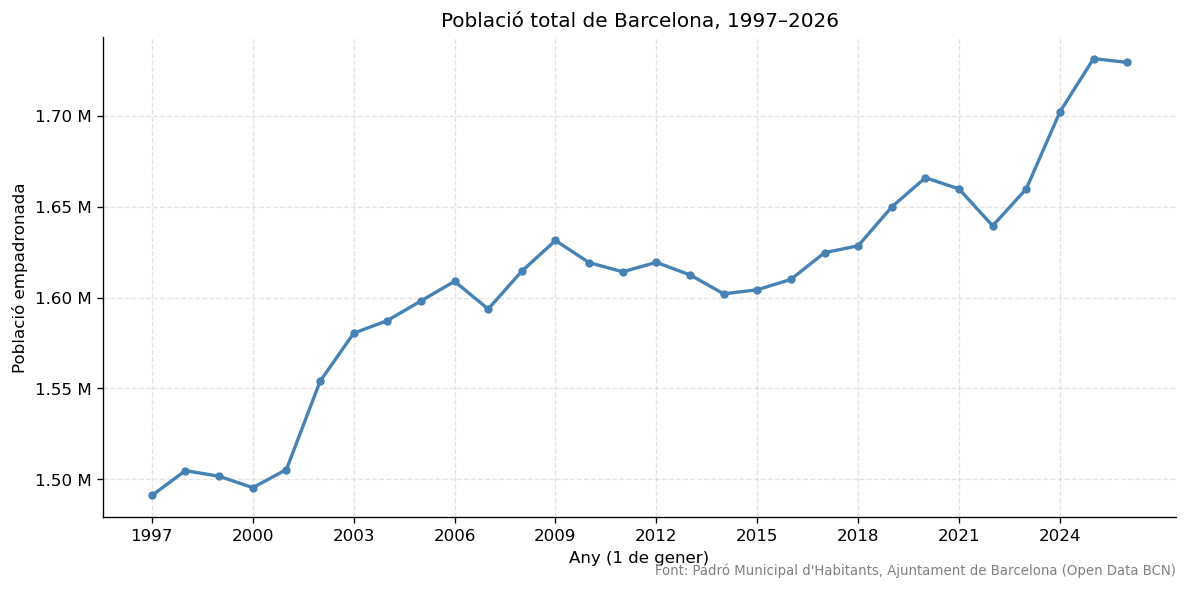

In [18]:
# 🔧 3.2.b — Població total per any (codis 1–6, ambdós sexes)
poblacio_any = df_serie.groupby("Any")["Valor"].sum()   # suma de tota la ciutat per any
print(poblacio_any.astype(int).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(poblacio_any.index, poblacio_any.values,
        color="steelblue", marker="o", markersize=4, linewidth=2)

# Format de l'eix Y en milions (1.729.409 → "1,73 M") per llegir-lo més fàcilment
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y / 1e6:.2f} M"))
ax.set_xticks(range(1997, 2027, 3))                     # una marca cada 3 anys

ax.set_title("Població total de Barcelona, 1997–2026")
ax.set_xlabel("Any (1 de gener)")
ax.set_ylabel("Població empadronada")
ax.text(1.0, -0.12, "Font: Padró Municipal d'Habitants, Ajuntament de Barcelona (Open Data BCN)",
        transform=ax.transAxes, ha="right", fontsize=8, color="gray")
plt.tight_layout()
plt.show()

### 3.3 🔧 Agregació per lloc de naixement

Per a la visualització principal, necessites la **suma total** (ambdós
sexes) de cada `LLOC_NAIX` per any.

Per resoldre l’exercici, es recomana utilitzar un encadenament d’operacions de Pandas (method chaining) similar al següent exemple:

```python
serie_lloc = (
    df_serie
    .groupby(["Any", "LLOC_NAIX"], as_index=False)["Valor"]
    .sum()
    .rename(columns={"Valor": "Total"})
)
```

Aquest estil de programació permet expressar de manera clara i concisa les diferents transformacions aplicades al conjunt de dades. En aquest exercici, es demana construir la taula pivot mitjançant un encadenament d’instruccions similar, combinant operacions com ara el filtratge de l’any 2026, la creació de la taula pivot, el càlcul de totals i el canvi de noms de columnes quan sigui necessari. L’objectiu és que el codi sigui llegible, fàcil de mantenir i coherent amb les bones pràctiques habituals en anàlisi de dades amb Pandas.

Crea un DataFrame `serie_lloc` amb columnes: `Any`, `LLOC_NAIX`,
`Lloc_Naix_Label`, `Total`.


In [19]:
# 🔧 3.3 — Total per any i lloc de naixement (sumant dones i homes)
serie_lloc = (
    df_serie
    .groupby(["Any", "LLOC_NAIX"], as_index=False)["Valor"]  # agrupem per any i lloc
    .sum()                                                    # sumem seccions i sexes
    .rename(columns={"Valor": "Total"})                       # nom més clar
    .merge(lloc_naix_dict, on="LLOC_NAIX", how="left")        # afegim l'etiqueta
    [["Any", "LLOC_NAIX", "Lloc_Naix_Label", "Total"]]        # ordre de columnes demanat
)

print("Shape:", serie_lloc.shape)   # 30 anys × 6 codis = 180 files
serie_lloc.head(12)

Shape: (180, 4)


,Any,LLOC_NAIX,Lloc_Naix_Label,Total
0,1997,1,Barcelona ciutat,887263.0
1,1997,2,Resta de Catalunya,128207.0
2,1997,3,Resta d’Espanya,424754.0
3,1997,4,Resta de la Unió Europea,12840.0
4,1997,5,Resta del món,38046.0
5,1997,6,No consta,5.0
6,1998,1,Barcelona ciutat,897918.0
7,1998,2,Resta de Catalunya,128470.0
8,1998,3,Resta d’Espanya,421131.0
9,1998,4,Resta de la Unió Europea,13845.0


### 3.4 🔧 Visualització: sèrie temporal

Fés un gràfic amb quatre línies (BCN, Resta Catalunya, Resta Espanya, Resta del món)
des del 1997 fins al 2026.

Requisits del gràfic:
- Títol i etiquetes dels eixos en català.
- Llegenda clara.
- Etiqueta amb el valor final de cada línia (2026) a la dreta.
- Paleta de colors coherent.
- Una anotació que marqui algun moment clau que pot haver tingut impacgte en la població (ex: crisi 2008, pandèmia 2020).

> 💡 Per al grup "Resta del món", agrupa els codis 4, 5 i 6.


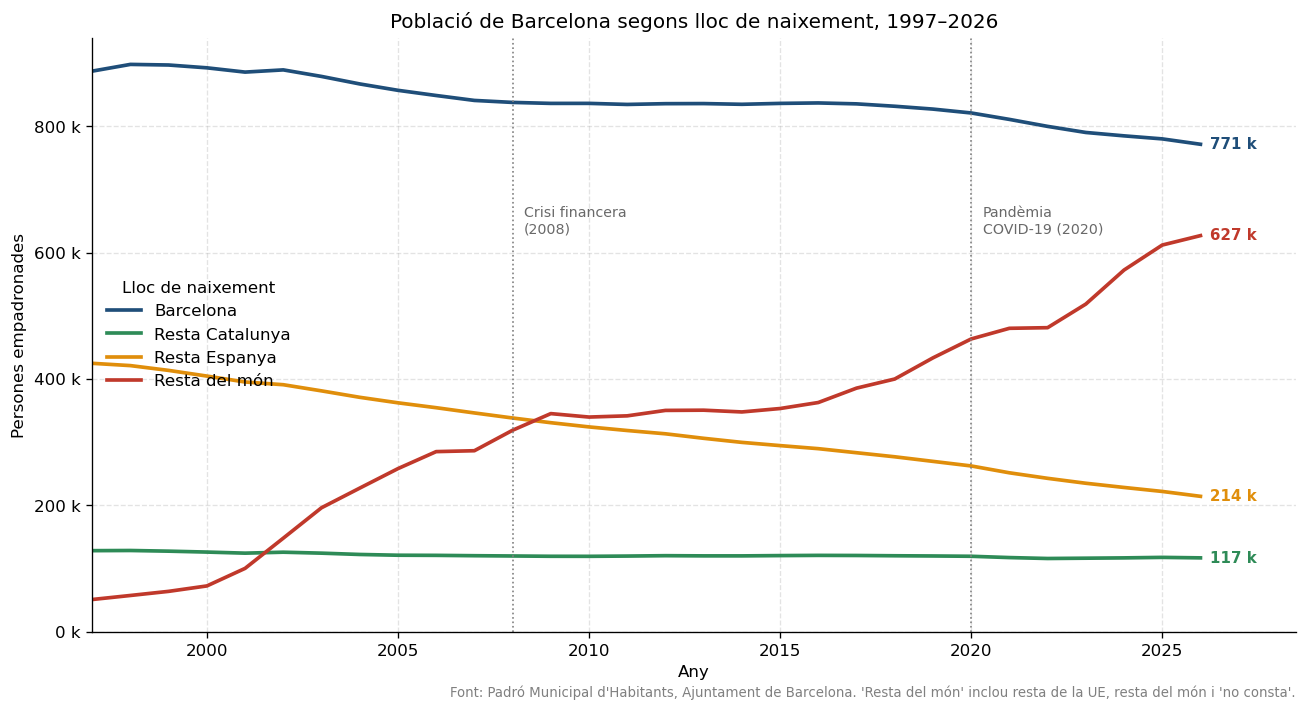

In [20]:
# 🔧 3.4 — Sèrie temporal per lloc de naixement

# Paleta comuna: la reutilitzarem al gràfic d'edat (5.5) perquè els colors siguin coherents
COLORS_GRUP = {
    "Barcelona":       "#1f4e79",   # blau fosc
    "Resta Catalunya": "#2e8b57",   # verd
    "Resta Espanya":   "#e08e0b",   # taronja
    "Resta del món":   "#c0392b",   # vermell
}

# Assignem cada codi LLOC_NAIX a un dels 4 grups. Els codis 4, 5 i 6 van a "Resta del món"
GRUP_PER_CODI = {1: "Barcelona", 2: "Resta Catalunya", 3: "Resta Espanya",
                 4: "Resta del món", 5: "Resta del món", 6: "Resta del món"}

# Taula ampla: una fila per any i una columna per grup (els codis 4–6 se sumen)
serie_grups = (
    serie_lloc
    .assign(Grup=serie_lloc["LLOC_NAIX"].map(GRUP_PER_CODI))  # nova columna amb el grup
    .pivot_table(index="Any", columns="Grup", values="Total", aggfunc="sum")
    [list(COLORS_GRUP)]                                        # ordre fix de les columnes
)

fig, ax = plt.subplots(figsize=(11, 6))

for grup, color in COLORS_GRUP.items():
    ax.plot(serie_grups.index, serie_grups[grup], color=color, linewidth=2.2, label=grup)
    # Etiqueta amb el valor final (2026) a la dreta de cada línia
    valor_final = serie_grups[grup].iloc[-1]
    ax.annotate(f"{valor_final / 1000:,.0f} k".replace(",", "."),
                xy=(2026, valor_final), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, fontweight="bold", color=color)

# Anotacions de moments clau: línia vertical + text
for any_clau, text in [(2008, "Crisi financera\n(2008)"), (2020, "Pandèmia\nCOVID-19 (2020)")]:
    ax.axvline(any_clau, color="gray", linestyle=":", linewidth=1)
    ax.text(any_clau + 0.3, 650_000, text, fontsize=8.5, color="dimgray", va="center")

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y / 1000:.0f} k"))
ax.set_xlim(1997, 2028.5)                     # espai a la dreta per a les etiquetes finals
ax.set_ylim(0, None)                          # l'eix Y comença a 0 per no exagerar canvis
ax.set_title("Població de Barcelona segons lloc de naixement, 1997–2026")
ax.set_xlabel("Any")
ax.set_ylabel("Persones empadronades")
ax.legend(title="Lloc de naixement", loc="center left", frameon=False)
ax.text(1.0, -0.11, "Font: Padró Municipal d'Habitants, Ajuntament de Barcelona. "
        "'Resta del món' inclou resta de la UE, resta del món i 'no consta'.",
        transform=ax.transAxes, ha="right", fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("grafic_serie.png", bbox_inches="tight", dpi=150)
plt.show()

---
## Part 4 — Estructura dels domicilis (2026)

Canviem de dataset: ara analitzem com es distribueixen els
**684.077 domicilis** de Barcelona per tipus d'estructura familiar.


### 4.1 🔧 Càrrega i exploració

Carrega `2026_domicilis_estructura.csv`.
Fes una inspecció equivalent a la de la Part 1:
shape, dtypes, nuls, valors únics de `TIPUS_DOMICILI`.


In [21]:
# 🔧 4.1 — Càrrega i exploració del fitxer de domicilis
df_dom = pd.read_csv(os.path.join(PATH_DOMICILIS, "2026_domicilis_estructura.csv"))

print("Shape:", df_dom.shape)
print("\nTipus de dades:")
print(df_dom.dtypes)
print("\nValors nuls per columna:")
print(df_dom.isna().sum())

# Valor ja és numèric (int64) en aquest fitxer, però ho comprovem igualment
print("\nFiles amb '..':", (df_dom["Valor"].astype(str) == "..").sum())

# Codis únics de tipus de domicili
print("\nValors únics de TIPUS_DOMICILI:", df_dom["TIPUS_DOMICILI"].nunique())
print(sorted(int(c) for c in df_dom["TIPUS_DOMICILI"].unique()))

# Comprovació: el total ha de coincidir amb els 684.077 domicilis de l'enunciat
print(f"\nTotal de domicilis: {df_dom['Valor'].sum():,}")
df_dom.head()

Shape: (12768, 9)

Tipus de dades:
Data_Referencia    object
Codi_Districte      int64
Nom_Districte      object
Codi_Barri          int64
Nom_Barri          object
AEB                 int64
Seccio_Censal       int64
Valor               int64
TIPUS_DOMICILI      int64
dtype: object

Valors nuls per columna:
Data_Referencia    0
Codi_Districte     0
Nom_Districte      0
Codi_Barri         0
Nom_Barri          0
AEB                0
Seccio_Censal      0
Valor              0
TIPUS_DOMICILI     0
dtype: int64

Files amb '..': 0

Valors únics de TIPUS_DOMICILI: 12
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

Total de domicilis: 684,077


,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,AEB,Seccio_Censal,Valor,TIPUS_DOMICILI
0,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,66,1
1,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,78,2
2,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,27,3
3,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,18,4
4,2026-01-01,1,Ciutat Vella,1,el Raval,1,1001,97,5


### 4.2 ✅ Diccionari de TIPUS_DOMICILI


In [22]:
# ✅ Codis de TIPUS_DOMICILI (dimensió 16)
tipus_dict = dims[dims["Desc_Dimensio"] == "TIPUS_DOMICILI"][
    ["Codi_Valor","Desc_Valor_CA"]
].rename(columns={"Codi_Valor": "TIPUS_DOMICILI",
                   "Desc_Valor_CA": "Tipus_Label"})
print(tipus_dict.to_string(index=False))


 TIPUS_DOMICILI                                                                 Tipus_Label
              1                                                    Una dona de 18 a 64 anys
              2                                                     Un home de 18 a 64 anys
              3                                                   Una dona de 65 anys i més
              4                                                    Un home de 65 anys i més
              5                                               Dues persones de 18 a 64 anys
              6                                              Dues persones de 65 anys i més
              7                      Dues persones: una de 18-64 anys i l'altra de 65 i més
              8                                 Dues persones o més totes majors de 18 anys
              9 Dues persones o més: una dona de 18 anys i més amb altres menors de 18 anys
             10  Dues persones o més: un home de 18 anys i més amb altres menors

### 4.3 🔧 Agregació i unió

Calcula el **nombre total de domicilis** per a cada codi `TIPUS_DOMICILI`
a nivell de tota la ciutat. Uneix amb `tipus_dict` per tenir l'etiqueta.
Ordena per nombre de domicilis de major a menor.


In [23]:
# 🔧 4.3 — Total de domicilis per tipus a tota la ciutat
dom_tipus = (
    df_dom
    .groupby("TIPUS_DOMICILI", as_index=False)["Valor"].sum()  # suma de totes les seccions
    .rename(columns={"Valor": "Domicilis"})
    .merge(tipus_dict, on="TIPUS_DOMICILI", how="left")         # afegim l'etiqueta
    .sort_values("Domicilis", ascending=False)                  # de major a menor
    .reset_index(drop=True)
)

# Percentatge de cada tipus sobre el total de domicilis
total_domicilis = dom_tipus["Domicilis"].sum()
dom_tipus["Pct"] = dom_tipus["Domicilis"] / total_domicilis * 100

print(f"Total de domicilis: {total_domicilis:,}")
dom_tipus

Total de domicilis: 684,077


,TIPUS_DOMICILI,Domicilis,Tipus_Label,Pct
0,8,130861,Dues persones o més totes majors de 18 anys,19.129572
1,5,92297,Dues persones de 18 a 64 anys,13.492195
2,11,77502,Tres persones o més: dues de 18 anys i més i l...,11.329426
3,3,70498,Una dona de 65 anys i més,10.305565
4,1,61792,Una dona de 18 a 64 anys,9.032901
5,2,61729,Un home de 18 a 64 anys,9.023692
6,6,59174,Dues persones de 65 anys i més,8.650196
7,12,49133,Altres domicilis amb una o més persones menors...,7.182379
8,7,37460,Dues persones: una de 18-64 anys i l'altra de ...,5.475992
9,4,24203,Un home de 65 anys i més,3.538052


### 4.4 🔧 Visualització: estructura dels domicilis

Crea un **gràfic de barres horitzontals** que mostri els 12 tipus
de domicili, amb:
- Etiquetes descriptives (del diccionari) a l'eix Y.
- Percentatge sobre el total al costat de cada barra.
- Colors que diferenciïn les llars unipersonals, les de dos, les de tres o més
  i les que inclouen menors.


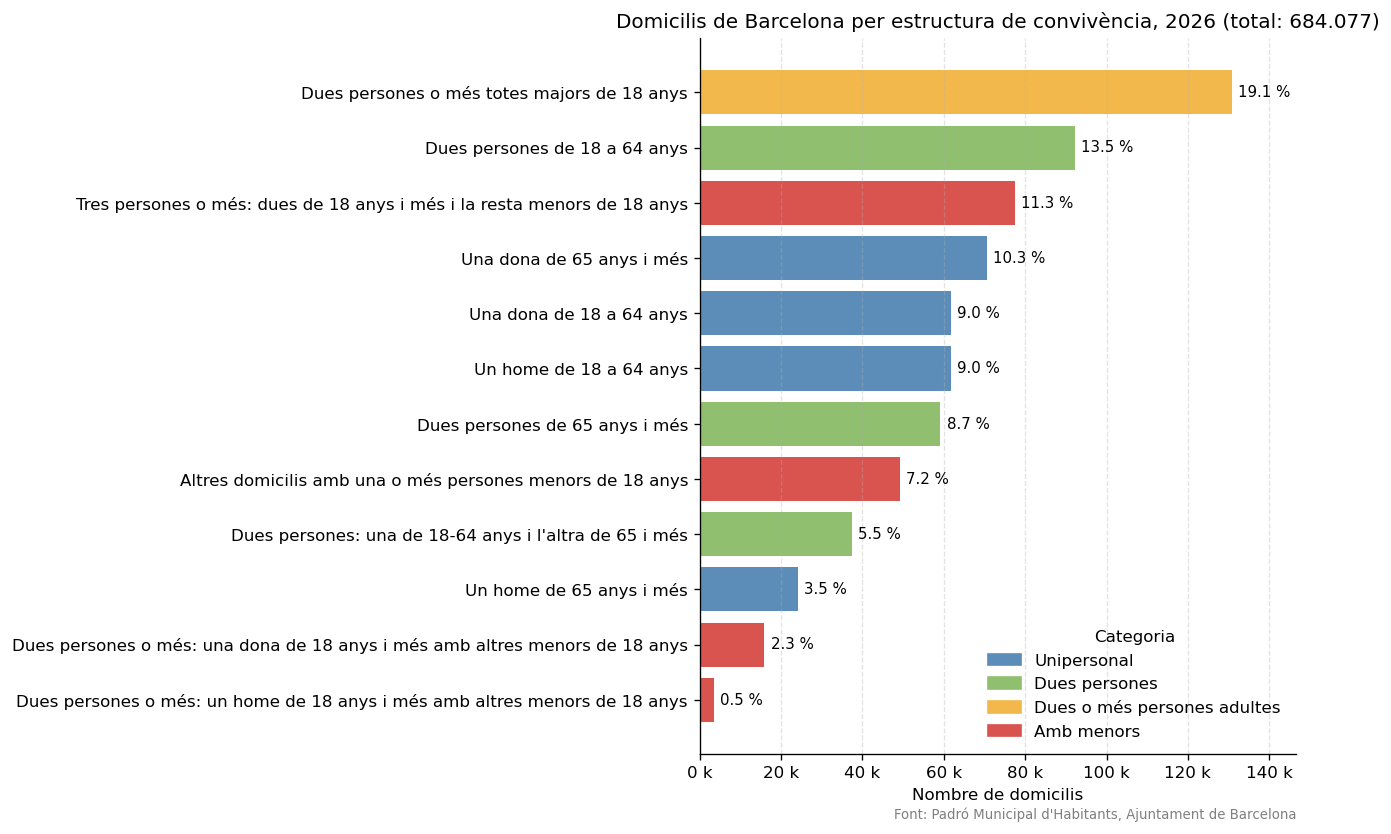

In [24]:
# 🔧 4.4 — Barres horitzontals per tipus de domicili

# Classifiquem els 12 codis en 4 categories (segons l'enunciat) i donem un color a cadascuna
CATEGORIA_DOM = {
    1: "Unipersonal", 2: "Unipersonal", 3: "Unipersonal", 4: "Unipersonal",
    5: "Dues persones", 6: "Dues persones", 7: "Dues persones",
    8: "Dues o més persones adultes",
    9: "Amb menors", 10: "Amb menors", 11: "Amb menors", 12: "Amb menors",
}
COLORS_DOM = {
    "Unipersonal":                 "#5b8db8",
    "Dues persones":               "#8fbf6f",
    "Dues o més persones adultes": "#f2b84b",
    "Amb menors":                  "#d9534f",
}

# Ordenem de menor a major perquè barh dibuixa de baix a dalt → la barra més gran queda a dalt
dades = dom_tipus.sort_values("Domicilis")
colors = dades["TIPUS_DOMICILI"].map(CATEGORIA_DOM).map(COLORS_DOM)

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(dades["Tipus_Label"], dades["Domicilis"], color=colors)

# Percentatge a la dreta de cada barra
for y, (n, pct) in enumerate(zip(dades["Domicilis"], dades["Pct"])):
    ax.text(n + 1500, y, f"{pct:.1f} %", va="center", fontsize=9)

# Llegenda manual: un rectangle de color per categoria
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=cat) for cat, c in COLORS_DOM.items()],
          title="Categoria", loc="lower right", frameon=False)

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x / 1000:.0f} k"))
ax.set_xlim(0, dades["Domicilis"].max() * 1.12)   # marge per als percentatges
ax.grid(axis="y", visible=False)                   # només graella vertical
total_txt = f"{total_domicilis:,}".replace(",", ".")   # 684077 → "684.077"
ax.set_title(f"Domicilis de Barcelona per estructura de convivència, 2026 (total: {total_txt})")
ax.set_xlabel("Nombre de domicilis")
ax.set_ylabel("")
ax.text(1.0, -0.09, "Font: Padró Municipal d'Habitants, Ajuntament de Barcelona",
        transform=ax.transAxes, ha="right", fontsize=8, color="gray")

plt.tight_layout()
plt.show()

### 4.5 🔧 Indicadors clau

Calcula i imprimeix:

a) Nombre i percentatge de domicilis on viu **una única persona**.
b) Nombre i percentatge de domicilis amb **presència de menors** (codis 9–12).
c) Comparació entre **dones soles ≥ 65 anys** i **homes sols ≥ 65 anys**.
   Quina és la ràtio? Quin fenomen sociodemogràfic reflecteix?


In [25]:
# 🔧 4.5 — Indicadors clau
# Sèrie indexada pel codi → podem accedir al total de cada tipus amb n_tipus[codi]
n_tipus = dom_tipus.set_index("TIPUS_DOMICILI")["Domicilis"]

def pct(n):
    """Percentatge d'un nombre de domicilis sobre el total de la ciutat."""
    return n / total_domicilis * 100

# a) Domicilis unipersonals = codis 1–4 (una sola persona, dona/home, jove/gran)
unipersonals = n_tipus.loc[[1, 2, 3, 4]].sum()
print(f"a) Domicilis unipersonals:     {unipersonals:,}  ({pct(unipersonals):.1f} %)")

# b) Domicilis amb menors de 18 anys = codis 9–12
amb_menors = n_tipus.loc[[9, 10, 11, 12]].sum()
print(f"b) Domicilis amb menors:       {amb_menors:,}  ({pct(amb_menors):.1f} %)")

# c) Persones grans que viuen soles: codi 3 (dona ≥ 65) i codi 4 (home ≥ 65)
dones_soles_65 = n_tipus[3]
homes_sols_65 = n_tipus[4]
ratio = dones_soles_65 / homes_sols_65
print(f"c) Dones soles ≥ 65 anys:      {dones_soles_65:,}  ({pct(dones_soles_65):.1f} %)")
print(f"   Homes sols ≥ 65 anys:       {homes_sols_65:,}  ({pct(homes_sols_65):.1f} %)")
print(f"   Ràtio dones / homes:        {ratio:.2f}  → per cada home gran que viu sol, n'hi ha {ratio:.1f} dones")

# Interpretació de la ràtio (c):
# Hi ha gairebé 3 dones grans vivint soles per cada home. Reflecteix la FEMINITZACIÓ DE
# L'ENVELLIMENT: les dones tenen una esperança de vida ~5 anys superior i, tradicionalment,
# es casaven amb homes més grans que elles, de manera que molt sovint enviuden i acaben
# vivint soles. Això té implicacions per a la soledat no desitjada i els serveis d'atenció
# domiciliària (teleassistència, ajuda a domicili), que s'han de dissenyar pensant sobretot
# en dones grans.

a) Domicilis unipersonals:     218,222  (31.9 %)
b) Domicilis amb menors:       146,063  (21.4 %)
c) Dones soles ≥ 65 anys:      70,498  (10.3 %)
   Homes sols ≥ 65 anys:       24,203  (3.5 %)
   Ràtio dones / homes:        2.91  → per cada home gran que viu sol, n'hi ha 2.9 dones


---
## Part 5 — Edat mitjana per lloc de naixement (2026)

Fins ara hem analitzat *quants* residents hi ha de cada origen.
Ara ens preguntem: *quina edat mitjana* té cada grup?
Aquesta informació és clau per entendre els fluxos migratoris
i les necessitats de serveis socials.


### 5.1 ✅ Estructura del dataset d'edat quinquennal

El fitxer `2026_edat_lloc_naix.csv` conté la població desagregada per
**grups d'edat quinquennals** (`EDAT_Q`), lloc de naixement i sexe.


In [26]:
# ✅ Carrega el dataset d'edat
df_edat = pd.read_csv(os.path.join(PATH_EDAT, "2026_edat_lloc_naix.csv"))
df_edat["Valor"] = pd.to_numeric(df_edat["Valor"], errors="coerce")
print("Shape:", df_edat.shape)
df_edat.head()


Shape: (14730, 9)


,Data_Referencia,Codi_Districte,Nom_Districte,Codi_Barri,Nom_Barri,Valor,LLOC_NAIX,EDAT_Q,SEXE
0,2026-01-01,1,Ciutat Vella,1,el Raval,813.0,1,0,1
1,2026-01-01,1,Ciutat Vella,1,el Raval,851.0,1,0,2
2,2026-01-01,1,Ciutat Vella,1,el Raval,648.0,1,1,1
3,2026-01-01,1,Ciutat Vella,1,el Raval,726.0,1,1,2
4,2026-01-01,1,Ciutat Vella,1,el Raval,526.0,1,2,1


### 5.2 ✅ Diccionari de grups d'edat quinquennals


In [27]:
# ✅ Codis EDAT_Q (dimensió 3)
edat_q_dict = dims[dims["Desc_Dimensio"] == "EDAT_Q"][
    ["Codi_Valor","Desc_Valor_CA"]
].rename(columns={"Codi_Valor":"EDAT_Q","Desc_Valor_CA":"Edat_Label"})
print(edat_q_dict.to_string(index=False))


 EDAT_Q Edat_Label
      0    <5 anys
      1   5-9 anys
      2 10-14 anys
      3 15-19 anys
      4 20-24 anys
      5 25-29 anys
      6 30-34 anys
      7 35-39 anys
      8 40-44 anys
      9 45-49 anys
     10 50-54 anys
     11 55-59 anys
     12 60-64 anys
     13 65-69 anys
     14 70-74 anys
     15 75-79 anys
     16 80-84 anys
     17 85-89 anys
     18 90-94 anys
     19 95-99 anys
     20  ≥100 anys
     21  No consta


### 5.3 🔧 Punt mig de cada grup

Per calcular l'edat mitjana ponderada necessitem assignar un
**punt mig** a cada grup quinquennal.

Completa el diccionari `MIDPOINTS` seguint la lògica:
- Grup 0 (<5 anys) → 2 anys
- Grup 1 (5-9 anys) → 7 anys
- …
- Grup 20 (≥100 anys) → 100 anys
- Grup 21 (No consta) → `None` (s'ha d'excloure del càlcul)


In [28]:
# 🔧 Completa el diccionari de punts mig
# El grup i cobreix les edats [5·i, 5·i + 4] → el seu punt mig (arrodonit) és 5·i + 2
#   grup 0 (0–4) → 2 · grup 1 (5–9) → 7 · ... · grup 19 (95–99) → 97
MIDPOINTS = {i: 5 * i + 2 for i in range(20)}   # grups 0–19
MIDPOINTS[20] = 100   # ≥ 100 anys: grup obert, prenem 100 com a aproximació
MIDPOINTS[21] = None  # No consta → s'exclou

# Comprova que tens 21 valors numèrics (grup 21 és None)
assert sum(1 for v in MIDPOINTS.values() if v is not None) == 21
assert MIDPOINTS[0] == 2 and MIDPOINTS[1] == 7 and MIDPOINTS[19] == 97
print("✓ MIDPOINTS correcte")

✓ MIDPOINTS correcte


### 5.4 🔧 Càlcul de l'edat mitjana ponderada

L'**edat mitjana ponderada** de cada grup es calcula com:

$$\bar{E} = \frac{\sum_i \text{midpoint}_i \cdot \text{poblaci\'o}_i}{\sum_i \text{poblaci\'o}_i}$$

Implementa la funció `edat_mitjana_per_lloc(df, midpoints)` que:
1. Afegeixi una columna `midpoint` a partir de `EDAT_Q`.
2. Exclogui les files amb `EDAT_Q == 21` (No consta).
3. Calculi l'edat mitjana per a cada codi `LLOC_NAIX` (1–6).
4. Retorni un DataFrame amb columnes `LLOC_NAIX` i `Edat_Mitjana`.

> 💡 Pista: `groupby(...).apply(lambda g: ...)`


In [29]:
def edat_mitjana_per_lloc(df: pd.DataFrame, midpoints: dict) -> pd.DataFrame:
    """Edat mitjana ponderada per població per a cada codi LLOC_NAIX.

    Edat mitjana = Σ (punt_mig · població) / Σ població
    """
    # 2. Excloem "No consta" (EDAT_Q == 21): no té edat i no es pot ponderar
    #    (es fa abans d'afegir midpoint perquè la columna quedi numèrica sense None)
    df = df[df["EDAT_Q"] != 21].copy()

    # 1. Afegim el punt mig de cada grup d'edat amb map (codi → edat)
    df["midpoint"] = df["EDAT_Q"].map(midpoints)

    # Traiem també les files amb Valor NaN (els ".." emmascarats): no aporten població coneguda
    df = df.dropna(subset=["Valor"])

    # 3. Numerador de la fórmula: edat × nombre de persones de cada fila
    df["edat_x_poblacio"] = df["midpoint"] * df["Valor"]

    # Sumem numerador i denominador per a cada lloc i els dividim
    resultat = df.groupby("LLOC_NAIX", as_index=False)[["edat_x_poblacio", "Valor"]].sum()
    resultat["Edat_Mitjana"] = resultat["edat_x_poblacio"] / resultat["Valor"]

    # 4. Retornem només les dues columnes demanades
    return resultat[["LLOC_NAIX", "Edat_Mitjana"]]

edat_m = edat_mitjana_per_lloc(df_edat, MIDPOINTS)
edat_m = edat_m.merge(lloc_naix_dict, on="LLOC_NAIX")
print(edat_m.to_string(index=False))

 LLOC_NAIX  Edat_Mitjana          Lloc_Naix_Label
         1     41.399045         Barcelona ciutat
         2     49.930071       Resta de Catalunya
         3     65.842986          Resta d’Espanya
         4     38.732642 Resta de la Unió Europea
         5     38.977925            Resta del món
         6     32.000000                No consta


### 5.5 🔧 Visualització i interpretació

**a)** Crea un gràfic de barres verticals que mostri l'edat mitjana
de cada grup de lloc de naixement, amb:
- Colors coherents amb els del gràfic de sèrie temporal.
- El valor numèric a sobre de cada barra.
- Una línia horitzontal discontínua que marqui l'edat mitjana global de la ciutat.

> 💡 Edat mitjana global estimada: calcula-la tu mateix a partir del dataset.


Edat mitjana global de Barcelona (2026): 44.1 anys


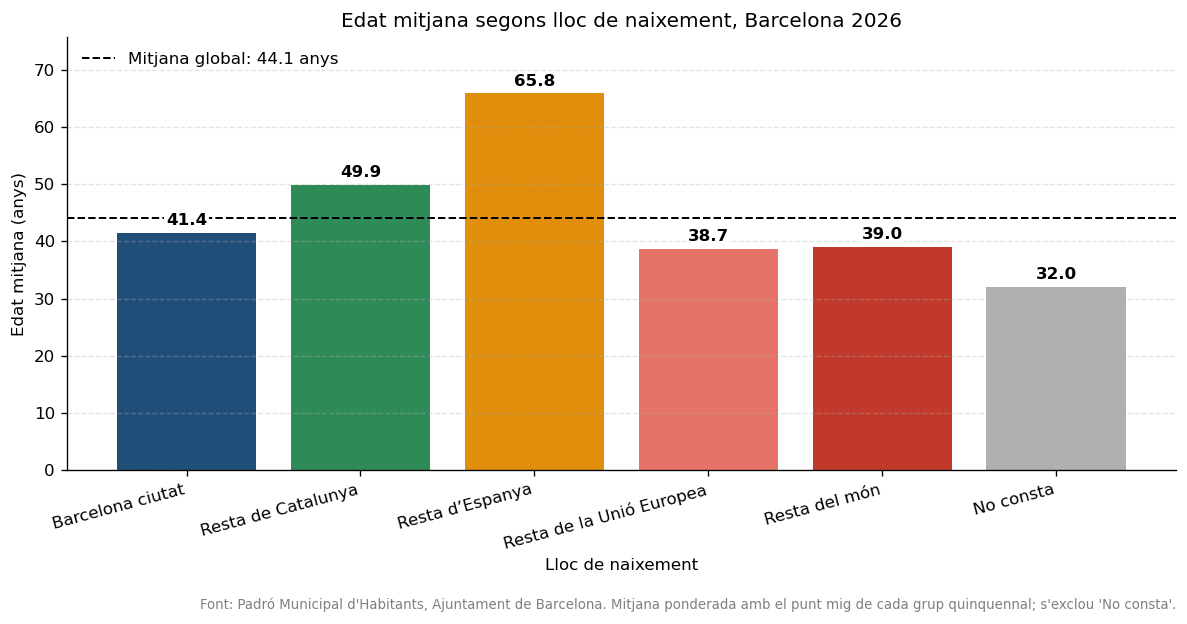

In [30]:
# 🔧 Gràfic d'edat mitjana

# Edat mitjana global de la ciutat: mateixa fórmula però sense separar per lloc
edat_valida = df_edat[(df_edat["EDAT_Q"] != 21) & df_edat["Valor"].notna()]
edat_global = ((edat_valida["EDAT_Q"].map(MIDPOINTS) * edat_valida["Valor"]).sum()
               / edat_valida["Valor"].sum())
print(f"Edat mitjana global de Barcelona (2026): {edat_global:.1f} anys")

# Colors coherents amb el gràfic de la sèrie temporal (3.4):
# codis 1–3 amb el color del seu grup; 4 i 5 són "Resta del món" → vermell (dues tonalitats),
# i 6 "No consta" en gris perquè és una categoria residual (molt poques persones).
COLORS_CODI = {
    1: COLORS_GRUP["Barcelona"],
    2: COLORS_GRUP["Resta Catalunya"],
    3: COLORS_GRUP["Resta Espanya"],
    4: "#e57368",                     # vermell clar (UE)
    5: COLORS_GRUP["Resta del món"],
    6: "#b0b0b0",
}

fig, ax = plt.subplots(figsize=(10, 5.5))
barres = ax.bar(edat_m["Lloc_Naix_Label"], edat_m["Edat_Mitjana"],
                color=edat_m["LLOC_NAIX"].map(COLORS_CODI))

# Valor numèric a sobre de cada barra
# (fons blanc perquè el número es llegeixi encara que toqui la línia de la mitjana)
ax.bar_label(barres, labels=[f"{e:.1f}" for e in edat_m["Edat_Mitjana"]],
             padding=3, fontsize=10, fontweight="bold",
             bbox=dict(facecolor="white", edgecolor="none", pad=1))

# Línia horitzontal discontínua amb la mitjana global
ax.axhline(edat_global, color="black", linestyle="--", linewidth=1.2,
           label=f"Mitjana global: {edat_global:.1f} anys")

ax.set_ylim(0, edat_m["Edat_Mitjana"].max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_title("Edat mitjana segons lloc de naixement, Barcelona 2026")
ax.set_xlabel("Lloc de naixement")
ax.set_ylabel("Edat mitjana (anys)")
ax.legend(loc="upper left", frameon=False)
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
ax.text(1.0, -0.32, "Font: Padró Municipal d'Habitants, Ajuntament de Barcelona. "
        "Mitjana ponderada amb el punt mig de cada grup quinquennal; s'exclou 'No consta'.",
        transform=ax.transAxes, ha="right", fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("grafic_edat_mitjana.png", bbox_inches="tight", dpi=150)
plt.show()

**b)** Interpreta el resultat:

- La diferència d'edat entre el grup nascut a la Resta d'Espanya i els
  nascuts a la Resta del Món és d'uns 27 anys. A quin fenomen històric
  es deu?
- Si la immigració estrangera cessa completament a partir del 2026,
  quin efecte esperes en l'edat mitjana global d'aquí a 20 anys?
  Argumenta qualitativament sense necessitat de fer projeccions numèriques.

**Resposta**

**1. Diferència de ~27 anys (65,8 vs 39,0 anys).** Es deu a dues onades migratòries de moments molt diferents. Els nascuts a la resta d'Espanya van arribar majoritàriament durant les **migracions interiors dels anys 1950–1970** (des d'Andalusia, Extremadura, Múrcia, Aragó...), atrets per la industrialització de Barcelona, quan eren joves. Aquesta onada es va aturar als anys 80, de manera que gairebé no s'hi incorporen persones noves: és una generació que ha envellit a la ciutat (avui tenen 60–80 anys o més). En canvi, la immigració estrangera és un fenomen **recent (a partir de ~2000)** i continu: arriben sobretot persones en edat de treballar (20–40 anys), i cada any n'arriben de noves que mantenen el grup jove. A més, els fills d'uns i altres nascuts aquí compten com a "Barcelona ciutat", no al grup dels pares.

**2. Si la immigració estrangera s'aturés el 2026**, esperaria que l'**edat mitjana global augmentés** clarament d'aquí a 20 anys. Ara mateix la immigració és el que frena l'envelliment: aporta adults joves i, indirectament, naixements. Sense aquesta entrada, el grup "resta del món" deixaria de renovar-se i envelliria un any per any (de ~39 a prop de ~59 anys de mitjana), i la natalitat de Barcelona, ja molt baixa, no seria suficient per compensar-ho. L'únic efecte en sentit contrari seria la mortalitat del grup nascut a la resta d'Espanya (el més gran), que reduiria el pes de les edats més altes, però no compensaria l'envelliment de la resta de la població. A més, la població total probablement disminuiria.

---
## Part 6 — Síntesi i comunicació

L'últim pas en qualsevol projecte de ciència de dades és
**comunicar els resultats** de forma clara i rigorosa.


### 6.1 🔧 Informe breu (Markdown)

Escriu, en aquesta mateixa cel·la Markdown, un informe d'entre
**300 i 500 paraules** que respongui les preguntes:

1. Quina és la tendència principal de la composició de la població
   barcelonina entre el 1997 i el 2026?
2. Quines implicacions té l'envelliment dels residents nascuts a la
   resta d'Espanya per als serveis socials de la ciutat?
3. Quin model de convivència predomina avui a Barcelona?
   Ha canviat respecte a dècades anteriors?
4. Quina limitació important té aquest dataset per respondre
   preguntes causals? (Per exemple: per què marxen les famílies?)

---

#### Informe: Barcelona 1997–2026, una ciutat que creix gràcies a la immigració

**1. Tendència principal.** Entre el 1997 i el 2026 la població empadronada ha passat d'1,49 a 1,73 milions de persones (+16 %), però aquest creixement prové gairebé tot de les persones nascudes a l'estranger. Els nascuts fora d'Espanya (resta de la UE i resta del món) han passat d'uns 51.000 (3 %) a més de 626.000 (36 %). En canvi, els nascuts a Barcelona han baixat de 887.000 a 771.000, i els nascuts a la resta d'Espanya s'han reduït a la meitat (de 425.000 a 214.000). El creixement no és lineal: hi ha un fort augment entre el 2000 i el 2008, una estabilització durant la crisi econòmica, una caiguda durant la pandèmia (2021–2022) i una nova acceleració a partir del 2023.

**2. Envelliment dels nascuts a la resta d'Espanya.** Aquest grup té una edat mitjana d'uns 66 anys, 22 anys per sobre de la mitjana de la ciutat (44 anys). Són les persones que van arribar en les migracions interiors dels anys 50–70 i ara són grans. Això implica una demanda creixent de serveis d'atenció a la dependència: ajuda a domicili, teleassistència, centres de dia, residències i atenció sanitària crònica. Com que molts viuen sols o en parella de gent gran, també caldrà prevenir la soledat no desitjada. Aquesta demanda arribarà al màxim en els propers 10–15 anys i després disminuirà, perquè el grup no es renova.

**3. Model de convivència.** El 2026 el tipus de domicili més habitual és el de dues o més persones adultes sense menors (19 %), i el **31,9 % dels domicilis són unipersonals**. Només un 21 % de les llars té menors de 18 anys. És a dir, la llar "clàssica" de parella amb fills ja és minoritària. Destaca que hi ha gairebé tres dones grans vivint soles per cada home gran en la mateixa situació, reflex de la feminització de l'envelliment. Amb les dades d'aquesta pràctica (només 2026) no podem mesurar el canvi respecte a dècades anteriors, però la caiguda de la natalitat, l'envelliment i l'augment de persones que viuen soles apunten a una reducció de la mida mitjana de les llars.

**4. Limitació per a preguntes causals.** El padró és un **registre administratiu de qui viu on en una data concreta**. Ens diu *quantes* persones hi ha i les seves característiques bàsiques, però no *per què* arriben o se'n van. No conté informació sobre ingressos, preu de l'habitatge, ocupació o motius del canvi de residència, i no segueix les persones individualment al llarg del temps. A més, compara fotos agregades de cada any: una caiguda dels nascuts a Barcelona pot ser per defuncions, per famílies que marxen a l'àrea metropolitana o per les dues coses alhora, i no ho podem distingir. Per tant, podem descriure correlacions (per exemple, entre crisi i aturada del creixement), però no establir relacions causals sense dades addicionals.

### 6.2 🔧 El millor gràfic

Tria **un sol gràfic** de tots els que has creat que consideres
el més informatiu o el que millor il·lustra la història de les dades.
Afina'l: títol clar, subtítol explicatiu, etiquetes, llegenda, font.

Justifica (3-4 frases) per què l'has triat per sobre dels altres.


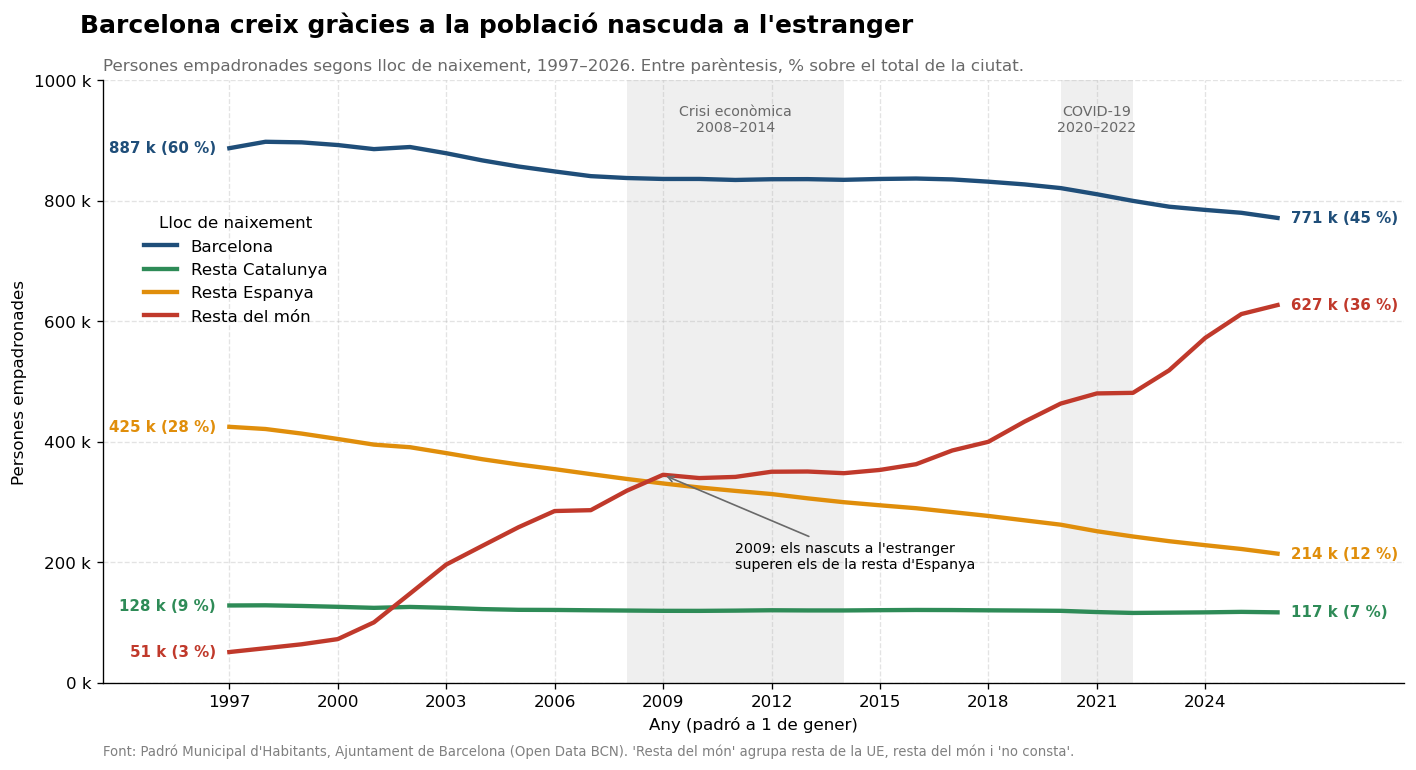

In [31]:
# 🔧 El teu millor gràfic, polít i complet
# Gràfic escollit: la sèrie temporal per lloc de naixement (3.4), millorada.
# Afegim el PERCENTATGE de cada grup sobre el total per veure el canvi de composició,
# no només el volum absolut.

total_any = serie_grups.sum(axis=1)                     # població total de cada any
pct_grups = serie_grups.div(total_any, axis=0) * 100    # % de cada grup sobre el total

fig, ax = plt.subplots(figsize=(12, 6.5))

for grup, color in COLORS_GRUP.items():
    ax.plot(serie_grups.index, serie_grups[grup], color=color, linewidth=2.6, label=grup)
    # Etiqueta inicial (1997) a l'esquerra i final (2026) a la dreta, amb valor i percentatge
    for any_, alineacio, desplac in [(1997, "right", -8), (2026, "left", 8)]:
        v, p = serie_grups.loc[any_, grup], pct_grups.loc[any_, grup]
        ax.annotate(f"{v / 1000:.0f} k ({p:.0f} %)", xy=(any_, v),
                    xytext=(desplac, 0), textcoords="offset points",
                    ha=alineacio, va="center", fontsize=9, fontweight="bold", color=color)

# Zones ombrejades per als períodes de crisi (en lloc d'una sola línia vertical)
for inici, fi, text in [(2008, 2014, "Crisi econòmica\n2008–2014"), (2020, 2022, "COVID-19\n2020–2022")]:
    ax.axvspan(inici, fi, color="gray", alpha=0.12, linewidth=0)
    ax.text((inici + fi) / 2, 960_000, text, ha="center", va="top", fontsize=8.5, color="dimgray")

# Punt de creuament: primer any en què "Resta del món" supera "Resta Espanya"
creuament = serie_grups.index[serie_grups["Resta del món"] > serie_grups["Resta Espanya"]][0]
ax.annotate(f"{creuament}: els nascuts a l'estranger\nsuperen els de la resta d'Espanya",
            xy=(creuament, serie_grups.loc[creuament, "Resta del món"]),
            xytext=(creuament + 2, 190_000), fontsize=8.5,
            arrowprops=dict(arrowstyle="->", color="dimgray"))

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y / 1000:.0f} k"))
ax.set_xlim(1993.5, 2029.5)
ax.set_ylim(0, 1_000_000)
ax.set_xticks(range(1997, 2027, 3))

# Títol (missatge principal) + subtítol (context)
fig.suptitle("Barcelona creix gràcies a la població nascuda a l'estranger",
             x=0.06, ha="left", fontsize=15, fontweight="bold")
ax.set_title("Persones empadronades segons lloc de naixement, 1997–2026. Entre parèntesis, % sobre el total de la ciutat.",
             loc="left", fontsize=10, color="dimgray")
ax.set_xlabel("Any (padró a 1 de gener)")
ax.set_ylabel("Persones empadronades")
ax.legend(title="Lloc de naixement", loc="upper left", bbox_to_anchor=(0.02, 0.80), frameon=False)
ax.text(0.0, -0.12, "Font: Padró Municipal d'Habitants, Ajuntament de Barcelona (Open Data BCN). "
        "'Resta del món' agrupa resta de la UE, resta del món i 'no consta'.",
        transform=ax.transAxes, ha="left", fontsize=8, color="gray")

plt.tight_layout()
plt.savefig("grafic_millor.png", bbox_inches="tight", dpi=150)
plt.show()

**Justificació de l'elecció**

He triat la sèrie temporal per lloc de naixement perquè és el gràfic que explica la història principal de les dades: Barcelona només ha crescut gràcies a la població nascuda a l'estranger, mentre que la resta de grups s'han reduït. A diferència del gràfic de domicilis o del d'edat mitjana, que són una foto del 2026, aquest mostra 30 anys d'evolució i permet relacionar els canvis amb fets concrets (la crisi del 2008 i la pandèmia). Les millores (percentatges a l'inici i al final, zones de crisi ombrejades i l'any en què els nascuts a l'estranger superen els de la resta d'Espanya) fan que el missatge s'entengui sense haver de llegir cap taula. També connecta amb el gràfic d'edat: els dos grups que es creuen són justament el més gran i el més jove de la ciutat.

### 6.3 🔧 Una pregunta oberta

Proposa **una pregunta** que les dades disponibles NO poden respondre
però que seria rellevant per entendre millor la demografia de Barcelona.
Indica quin dataset addicional caldria per respondre-la.

---

**Pregunta:** *Les famílies amb fills que marxen de Barcelona ho fan per l'augment del preu de l'habitatge? On van a viure?*

**Per què el padró no ho pot respondre:** el padró només compta qui viu a la ciutat cada 1 de gener. Veiem que hi ha menys nascuts a Barcelona i pocs domicilis amb menors, però no sabem quantes famílies han marxat, on han anat ni per quin motiu.

**Dades addicionals necessàries:**
- **Estadística de Variacions Residencials (INE / Idescat):** altes i baixes del padró amb origen i destinació de cada canvi de residència, per edat i tipus de llar. Permetria saber si les famílies marxen sobretot a l'àrea metropolitana.
- **Preus de lloguer i compravenda per barri (Open Data BCN / INCASÒL, fiances de lloguer):** per relacionar els barris d'on surten més famílies amb l'evolució del preu de l'habitatge.
- Idealment, una **enquesta** als qui marxen sobre els motius (habitatge, feina, escola, qualitat de vida), ja que les dades administratives només mostren correlacions.